# Fast Fashion Network: market model and hub removal (Model 2)

Student Name : Radiah, Flora

Five producer countries (X–W) sell clothing to two markets (A, B). Producer sizes come from the real top 5 exporters, the market sets one world price, and we test what happens when the biggest producer (the hub) loses factories.

## Setup

In [1]:
import os, zipfile
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.optimize import brentq      # finds the price where supply = demand

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

# Colours: one per producer (biggest first) and one for the markets
PROD_COLORS = ["#264653", "#2a9d8f", "#d9a62e", "#f4a261", "#e76f51"]
MARKET_COLOR = "#6d597a"
ATTACK_COLOR, RANDOM_COLOR = "#e76f51", "#2a9d8f"

# Find the dataset: local folder -> zip -> clone the repo (Colab)
DATA = "fast_fashion_dataset"
if not os.path.isdir(DATA):
    if os.path.isfile(DATA + ".zip"):
        zipfile.ZipFile(DATA + ".zip").extractall(".")
    else:
        if not os.path.isdir("repo"):
            os.system("git clone -q https://github.com/radiah23/Modeling-Fast-Fashion-Supply-Chain.git repo")
        DATA = "repo/fast_fashion_dataset"

---
# 1. The world

The real top 5 clothing exporters (China, Bangladesh, Vietnam, Turkey, India) have very unequal sizes. Sorted by size, their shares follow a power law in rank, $s_r \propto r^{-\alpha}$. We fit $\alpha$ once and use it to build **generic producers X, Y, Z, V, W** whose shares add up to 1. All producers get the same wage, so size is the only difference between them. Markets A and B take 70% and 30% of demand, like the EU and the USA.

In [2]:
prod = pd.read_csv(f"{DATA}/producers.csv").nlargest(5, "exports_2024_usd_bn")
cons = pd.read_csv(f"{DATA}/consumers.csv").set_index("iso3").loc[["EU", "USA"]]

# Hub strength alpha: slope of log(share) vs log(rank)
real_share = prod.exports_2024_usd_bn.values / prod.exports_2024_usd_bn.sum()
rank = np.arange(1, 6)
ALPHA = -np.polyfit(np.log(rank), np.log(real_share), 1)[0]

PRODUCERS, MARKETS = ["X", "Y", "Z", "V", "W"], ["A", "B"]
P0 = rank ** -ALPHA; P0 = P0 / P0.sum()                                   # producer shares, add up to 1
C0 = (cons.imports_2023_usd_bn / cons.imports_2023_usd_bn.sum()).values  # market shares (EU, USA)
COLORS = dict(zip(PRODUCERS, PROD_COLORS))

print(f"alpha = {ALPHA:.2f}")
display(pd.DataFrame({"real country": prod.country.values, "real share": real_share.round(3),
                      "generic": PRODUCERS, "model share": P0.round(3)}))

alpha = 1.42


,real country,real share,generic,model share
0,China,0.608,X,0.549
1,Bangladesh,0.142,Y,0.205
2,Vietnam,0.125,Z,0.115
3,Turkey,0.066,V,0.076
4,India,0.060,W,0.056


---
# 2. The network

Edges go from producers to markets. We only know the totals, so we use **proportional allocation**, $w_{ij} = P_i \cdot C_j / Q$: each producer splits its output in the same proportions as the markets' demand. This is the standard (maximum-entropy) assumption and the same idea as the null model $k_i k_j / 2m$ in modularity (Week 5).

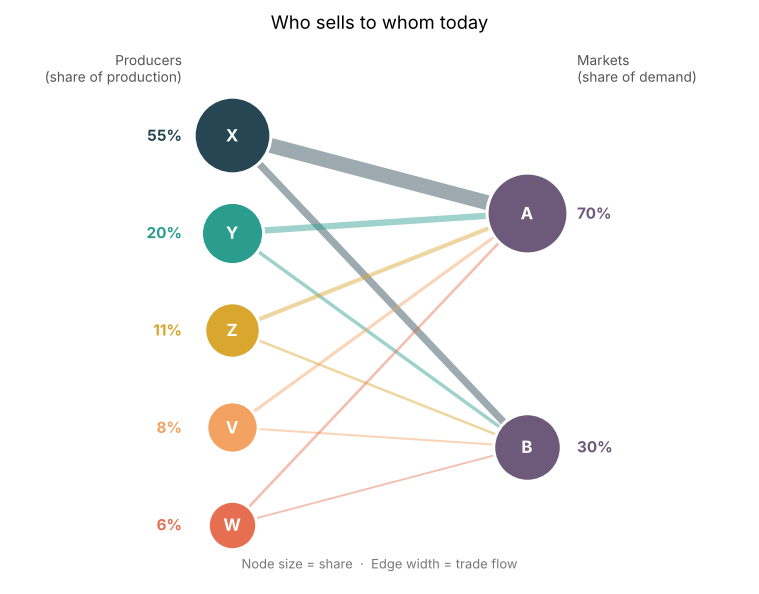

In [3]:
def build_network(P, C):
    """Bipartite producer -> market network with proportional allocation."""
    G = nx.DiGraph()
    for i, p in zip(PRODUCERS, P): G.add_node(i, size=p, kind="producer")
    for j, c in zip(MARKETS, C):   G.add_node(j, size=c, kind="market")
    for i, p in zip(PRODUCERS, P):
        for j, c in zip(MARKETS, C):
            G.add_edge(i, j, weight=p * c / C.sum())
    return G

def draw_network(G, ax, title, before=None):
    """Producers left, markets right. Node area ~ size, edge width ~ flow.
    before = network before a shock: shows each node's % change and a dashed ring on the hit producer."""
    pos = {n: (0, -k) for k, n in enumerate(PRODUCERS)}
    pos.update({"A": (1, -0.8), "B": (1, -3.2)})
    ref = before if before is not None else G             # same edge scale before and after a shock
    wmax = max(d["weight"] for *_, d in ref.edges(data=True))
    for u, v, d in G.edges(data=True):
        ax.plot(*zip(pos[u], pos[v]), color=COLORS[u], lw=0.8 + 9 * d["weight"] / wmax, alpha=0.45,
                solid_capstyle="round", zorder=1)
    for n in G:
        x, y = pos[n]; s = G.nodes[n]["size"]
        col = COLORS.get(n, MARKET_COLOR)
        ax.scatter(x, y, s=300 + 3000 * np.sqrt(s), color=col, edgecolor="white", linewidth=2, zorder=3)
        ax.text(x, y, n, ha="center", va="center", color="white", fontweight="bold", fontsize=11, zorder=4)
        label = f"{100 * s:.0f}%"
        if before is not None:                              # add the change, e.g. "27%  (-50%)"
            ch = 100 * (s / before.nodes[n]["size"] - 1)
            label += f"  ({ch:+.0f}%)"
        side = -1 if G.nodes[n]["kind"] == "producer" else 1
        ax.text(x + side * 0.17, y, label, ha="right" if side < 0 else "left", va="center",
                fontsize=10, color=col, fontweight="bold")
        if before is not None and n in PRODUCERS and s < before.nodes[n]["size"] - 1e-9:
            ax.scatter(x, y, s=300 + 3000 * np.sqrt(before.nodes[n]["size"]), facecolor="none",
                       edgecolor="#333333", linestyle="--", linewidth=1.3, zorder=2)
    ax.text(-0.17, 0.55, "Producers\n(share of production)", ha="right", fontsize=9, color="#555555")
    ax.text(1.17, 0.55, "Markets\n(share of demand)", ha="left", fontsize=9, color="#555555")
    ax.text(0.5, -4.45, "Node size = share  ·  Edge width = trade flow" +
            ("  ·  dashed ring = size before" if before is not None else ""),
            ha="center", fontsize=8.5, color="#777777")
    ax.set_xlim(-0.75, 1.75); ax.set_ylim(-4.6, 1.0); ax.set_title(title, fontsize=12); ax.axis("off")

G0 = build_network(P0, C0)
fig, ax = plt.subplots(figsize=(7, 5.5))
draw_network(G0, ax, "Who sells to whom today")
plt.tight_layout(); plt.show()

X is the hub: it makes 55% of all clothing, and its flow to market A is the thickest edge in the network. Y–W together make less than X alone.

---
# 3. The market

- **Supply:** $S_i(p) = \min(K_i,\; s_i\,(p - c))$: producers make more when the price is higher, up to their capacity $K_i$.
- **Demand:** $D_j(p) = A_j - B_j\,p$: markets buy less when the price is higher.
- **Equilibrium:** one world price $p^*$ where total supply = total demand.

The curves are set so that today's market clears at $p^* = 1$ with the shares above.

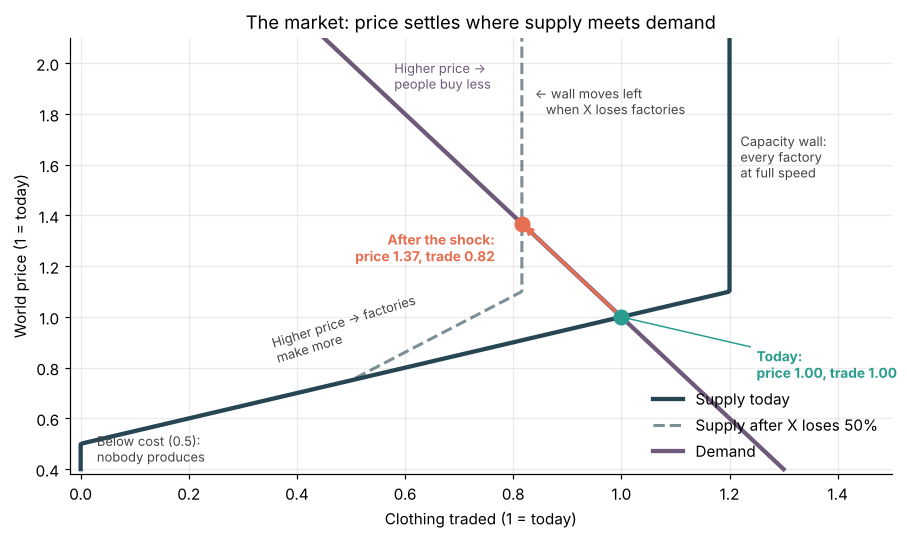

In [4]:
PARAMS = dict(cost=0.5,     # unit cost c (same for every producer; price is normalized to 1)
              eps=0.5,      # demand elasticity: B_j = eps * C_j
              spare=0.2)    # spare capacity: K_i = P_i * (1 + spare)

slope = P0 / (1 - PARAMS["cost"])             # supply slope, so S_i(1) = P_i
K0 = P0 * (1 + PARAMS["spare"])               # capacity
B = PARAMS["eps"] * C0                        # demand slope
A = C0 + B                                    # demand intercept, so D_j(1) = C_j

supply = lambda p, K=K0: np.minimum(K, np.maximum(0, slope * (p - PARAMS["cost"])))
demand = lambda p: np.maximum(0, A - B * p)

def equilibrium(K=K0):
    """World price where total supply = total demand, with production and consumption."""
    p = brentq(lambda p: demand(p).sum() - supply(p, K).sum(), 1e-6, 50)
    return p, supply(p, K), demand(p)

p_star, S_star, D_star = equilibrium()

# The same market after X loses half of its factories (used to show how a shock works)
K_half = K0.copy(); K_half[0] = 0.5 * P0[0]
p_new, S_new, _ = equilibrium(K_half)

grid = np.linspace(0.4, 2.1, 400)
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot([supply(p).sum() for p in grid], grid, color=PROD_COLORS[0], lw=2.8, label="Supply today")
ax.plot([supply(p, K_half).sum() for p in grid], grid, color=PROD_COLORS[0], lw=2, ls="--", alpha=0.6,
        label="Supply after X loses 50%")
ax.plot([demand(p).sum() for p in grid], grid, color=MARKET_COLOR, lw=2.8, label="Demand")
ax.scatter(S_star.sum(), p_star, color=RANDOM_COLOR, s=90, zorder=5)
ax.scatter(S_new.sum(), p_new, color=ATTACK_COLOR, s=90, zorder=5)
ax.annotate("", xy=(S_new.sum(), p_new), xytext=(S_star.sum(), p_star),
            arrowprops=dict(arrowstyle="->", color=ATTACK_COLOR, lw=2))

note = dict(fontsize=8.5, color="#444444")
ax.annotate("Today:\nprice 1.00, trade 1.00", xy=(1, 1), xytext=(1.25, 0.76), color=RANDOM_COLOR,
            fontsize=9, fontweight="bold", arrowprops=dict(arrowstyle="-", color=RANDOM_COLOR, lw=1))
ax.text(S_new.sum() - 0.05, p_new - 0.03, f"After the shock:\nprice {p_new:.2f}, trade {S_new.sum():.2f}",
        ha="right", va="top", color=ATTACK_COLOR, fontsize=9, fontweight="bold")
ax.text(0.03, 0.43, "Below cost (0.5):\nnobody produces", **note)
ax.text(0.35, 0.82, "Higher price → factories\nmake more", rotation=17, **note)
ax.text(1.22, 1.55, "Capacity wall:\nevery factory\nat full speed", **note)
ax.text(0.84, 1.8, "← wall moves left\n   when X loses factories", ha="left", **note)
ax.text(0.58, 1.9, "Higher price →\npeople buy less", color=MARKET_COLOR, fontsize=8.5)
ax.set_xlim(-0.02, 1.5); ax.set_ylim(0.38, 2.1)
ax.set_xlabel("Clothing traded (1 = today)"); ax.set_ylabel("World price (1 = today)")
ax.set_title("The market: price settles where supply meets demand", fontsize=12)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

Today the market sits at price 1 and trade 1. When X loses half its factories, the capacity wall moves left, past today's trade. The price rises along the demand line until buyers only want what can still be made: price 1.37, trade 0.82.

---
# 4. Removing the hub

- **Targeted attack:** X loses a share $f$ of its factories, so its capacity becomes $(1-f)\,P_X$.
- **Random failure (control):** a random producer loses the same share. We run all 5 and average them (the exact expected value).

After each shock we solve the new equilibrium (Week 4: failure vs. attack).

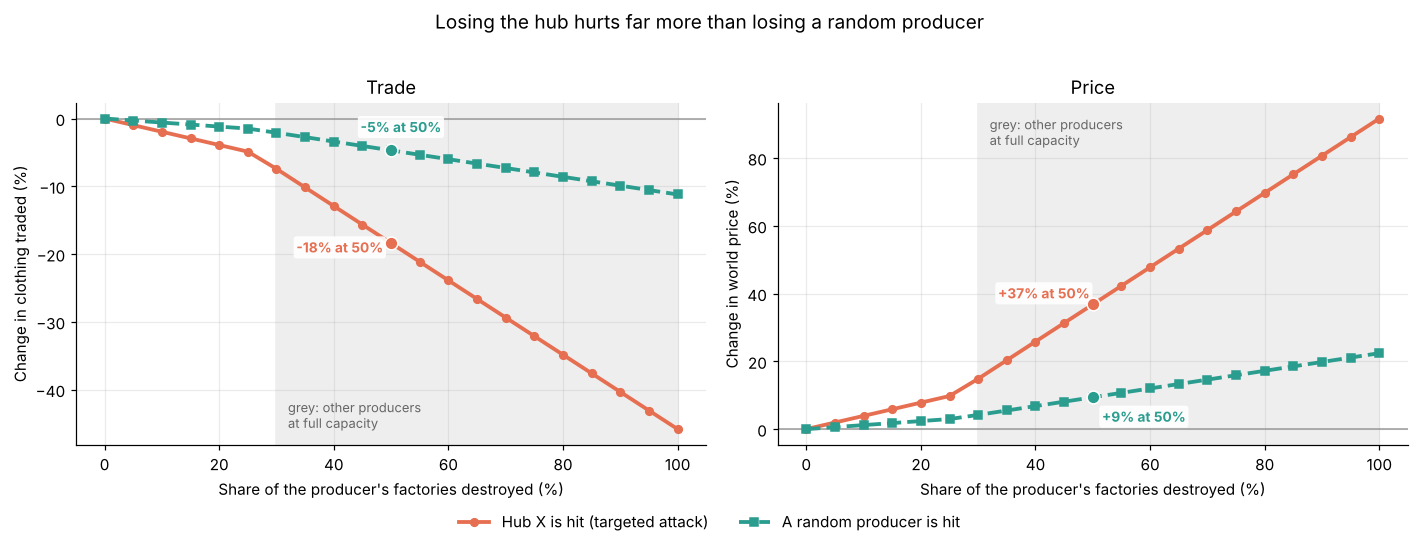

In [5]:
def shocked(k, f):
    """Capacity after producer k loses a share f of its factories."""
    K = K0.copy(); K[k] = min(K[k], (1 - f) * P0[k]); return K

F = np.linspace(0, 1, 21)
attack = np.array([equilibrium(shocked(0, f))[:2] for f in F], dtype=object)
att_p = np.array([a[0] for a in attack]);  att_q = np.array([a[1].sum() for a in attack])
rnd = [[equilibrium(shocked(k, f)) for f in F] for k in range(5)]
rnd_p = np.mean([[r[0] for r in row] for row in rnd], axis=0)
rnd_q = np.mean([[r[1].sum() for r in row] for row in rnd], axis=0)

# From which f on are all other producers at full capacity?
others_full = np.array([np.allclose(equilibrium(shocked(0, f))[1][1:], K0[1:]) for f in F])
f_full = F[others_full.argmax()] * 100

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, y1, y2, lab, ttl in [(ax[0], 100 * (att_q - 1), 100 * (rnd_q - 1), "Change in clothing traded (%)", "Trade"),
                             (ax[1], 100 * (att_p - 1), 100 * (rnd_p - 1), "Change in world price (%)", "Price")]:
    a.axvspan(f_full, 100, color="#eeeeee", zorder=0)
    ytxt, va = (0.04, "bottom") if a is ax[0] else (0.96, "top")      # keep the note away from the curves
    a.text(f_full + 2, ytxt, "grey: other producers\nat full capacity", transform=a.get_xaxis_transform(),
           ha="left", va=va, fontsize=8.5, color="#666666")
    a.axhline(0, color="#999999", lw=1)
    a.plot(F * 100, y1, "o-", color=ATTACK_COLOR, lw=2.5, ms=5, label="Hub X is hit (targeted attack)")
    a.plot(F * 100, y2, "s--", color=RANDOM_COLOR, lw=2.5, ms=5, label="A random producer is hit")
    k = int(np.argmin(np.abs(F - 0.5)))                     # label both curves at 50% destroyed
    offs = {ATTACK_COLOR: (-62, -6) if a is ax[0] else (-62, 4), RANDOM_COLOR: (-20, 12) if a is ax[0] else (6, -16)}
    for yy, col in [(y1, ATTACK_COLOR), (y2, RANDOM_COLOR)]:
        a.scatter(50, yy[k], s=70, color=col, edgecolor="white", zorder=5)
        a.annotate(f"{yy[k]:+.0f}% at 50%", (50, yy[k]), textcoords="offset points", xytext=offs[col],
                   color=col, fontweight="bold", fontsize=9,
                   bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.9))
    a.set_xlabel("Share of the producer's factories destroyed (%)"); a.set_ylabel(lab); a.set_title(ttl, fontsize=12)
h, l = ax[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Losing the hub hurts far more than losing a random producer", fontsize=12.5, y=1.02)
plt.tight_layout(); plt.show()

Losing the hub costs far more than a random failure of the same size. The other producers can grow by at most 20% (their spare capacity). In the grey area they are all at full capacity, so nothing more can be replaced: from there on every factory X loses is clothing nobody gets, and the price climbs faster. A random failure usually hits a small producer, which the others easily cover.

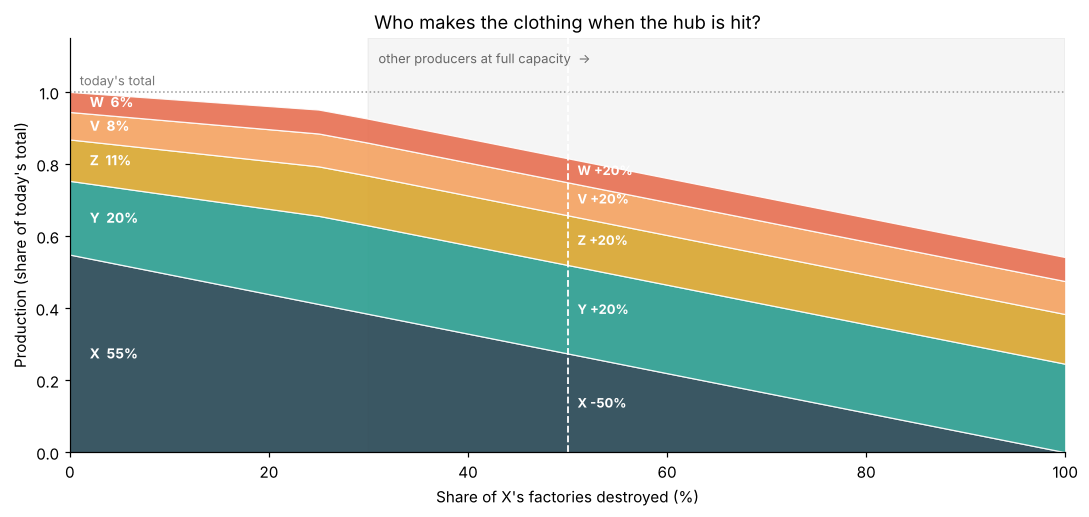

In [6]:
# Who makes the clothing as X loses factories? Output of every producer (share of today's total)
S_att = np.array([equilibrium(shocked(0, f))[1] for f in F])        # rows: f, columns: X..W

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.stackplot(F * 100, S_att.T, colors=PROD_COLORS, alpha=0.9, edgecolor="white", linewidth=0.8)
ax.axvspan(f_full, 100, color="#000000", alpha=0.04, zorder=0)
ax.axhline(1, color="#999999", lw=1, ls=":")
ax.text(1, 1.01, "today's total", fontsize=8.5, color="#777777", va="bottom")

# Name each band at the left edge, inside its own colour
mid = np.cumsum(S_att[0]) - S_att[0] / 2
for n, y, col in zip(PRODUCERS, mid, PROD_COLORS):
    ax.text(2, y, f"{n}  {100 * S_att[0][PRODUCERS.index(n)]:.0f}%", va="center", fontsize=9,
            color="white", fontweight="bold")
# ... and their output at 50% destroyed, with the change
k = int(np.argmin(np.abs(F - 0.5)))
mid50 = np.cumsum(S_att[k]) - S_att[k] / 2
for i, (n, y) in enumerate(zip(PRODUCERS, mid50)):
    ch = 100 * (S_att[k][i] / P0[i] - 1)
    ax.text(51, y, f"{n} {ch:+.0f}%", va="center", fontsize=8.5, color="white", fontweight="bold")
ax.axvline(50, color="white", lw=1.2, ls="--")
ax.text(f_full + 1, 1.08, "other producers at full capacity  →", fontsize=8.5, color="#666666")

ax.set_xlim(0, 100); ax.set_ylim(0, 1.15)
ax.set_xlabel("Share of X's factories destroyed (%)"); ax.set_ylabel("Production (share of today's total)")
ax.set_title("Who makes the clothing when the hub is hit?", fontsize=12)
ax.grid(False); plt.tight_layout(); plt.show()

Y, Z, V and W step in, but each can only grow by 20%. Once they are all at full capacity (from about 30%), the stack shrinks with every factory X loses: that missing clothing is the trade drop in the plot above.

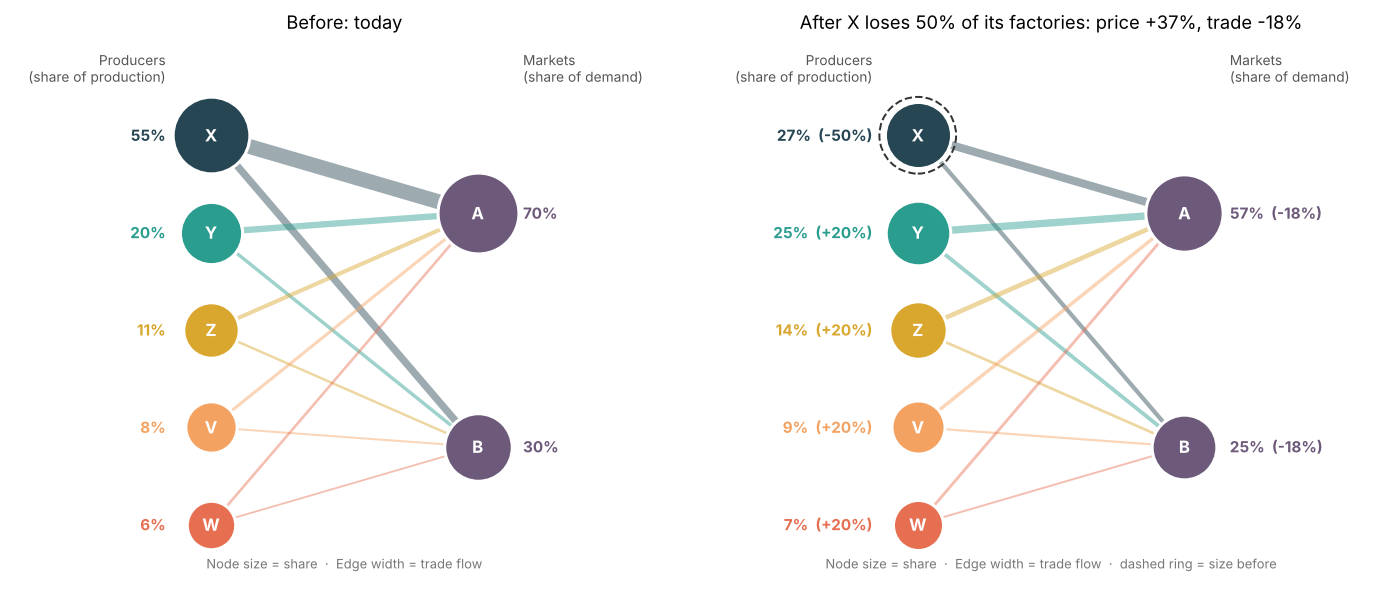

In [7]:
# The network before and after X loses half of its factories (numbers = share of today's trade, change in brackets)
p_half, S_half, D_half = equilibrium(shocked(0, 0.5))
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
draw_network(G0, ax[0], "Before: today")
draw_network(build_network(S_half, D_half), ax[1],
             f"After X loses 50% of its factories: price {100*(p_half-1):+.0f}%, trade {100*(S_half.sum()-1):+.0f}%", before=G0)
plt.tight_layout(); plt.show()

---
**AI Prompts Used Throughout the Whole Assignment**

1. (add the prompts you used here, as in the Vilar notebook)